# **Inteligencia Artificial y Aprendizaje Automático**
## **Maestría en Inteligencia Artificial Aplicada**

**Dr. Iván Reyes Amezcua**

**Tecnológico de Monterrey**
### **Actividad Individual: Dataset - Notebook**


#### **Nombre: Luis Alfredo Ojeda Benito**
#### **Matrícula: A01750598**

In [6]:
import pandas as pd
import kagglehub
import mlflow
import os

# 1. Configurarcion de servidor local de MLflow
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("TC5061_Notebook_Baseline_OjedaLuis")

# 2. Descargar el dataset de Steam localmente
path = kagglehub.dataset_download("nikdavis/steam-store-games")
print("Ruta de los archivos descargados:", path)

# 3. Cargar los datos en un DataFrame de Pandas
csv_path = os.path.join(path, "steam.csv")
df = pd.read_csv(csv_path)

# 4. Descripción inicial del dataset 
print(f"\nEl dataset contiene {df.shape[0]} registros (juegos) y {df.shape[1]} variables.\n")

# Mostrar los tipos de datos y valores no nulos
df.info()

# Previsualizar las primeras 5 filas
df.head()

Ruta de los archivos descargados: C:\Users\Jimmy\.cache\kagglehub\datasets\nikdavis\steam-store-games\versions\3

El dataset contiene 27075 registros (juegos) y 18 variables.

<class 'pandas.DataFrame'>
RangeIndex: 27075 entries, 0 to 27074
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   appid             27075 non-null  int64  
 1   name              27075 non-null  str    
 2   release_date      27075 non-null  str    
 3   english           27075 non-null  int64  
 4   developer         27074 non-null  str    
 5   publisher         27061 non-null  str    
 6   platforms         27075 non-null  str    
 7   required_age      27075 non-null  int64  
 8   categories        27075 non-null  str    
 9   genres            27075 non-null  str    
 10  steamspy_tags     27075 non-null  str    
 11  achievements      27075 non-null  int64  
 12  positive_ratings  27075 non-null  int64  
 13  negative_ratings

,appid,name,release_date,english,developer,publisher,platforms,required_age,categories,genres,steamspy_tags,achievements,positive_ratings,negative_ratings,average_playtime,median_playtime,owners,price
0,10,Counter-Strike,2000-11-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,124534,3339,17612,317,10000000-20000000,7.19
1,20,Team Fortress Classic,1999-04-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,3318,633,277,62,5000000-10000000,3.99
2,30,Day of Defeat,2003-05-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Valve Anti-Cheat enabled,Action,FPS;World War II;Multiplayer,0,3416,398,187,34,5000000-10000000,3.99
3,40,Deathmatch Classic,2001-06-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,Action;FPS;Multiplayer,0,1273,267,258,184,5000000-10000000,3.99
4,50,Half-Life: Opposing Force,1999-11-01,1,Gearbox Software,Valve,windows;mac;linux,0,Single-player;Multi-player;Valve Anti-Cheat en...,Action,FPS;Action;Sci-fi,0,5250,288,624,415,5000000-10000000,3.99


Análisis de la Estructura del Dataset

Dimensiones Generales:

El conjunto de datos contiene 27,075 registros (cada uno representando un videojuego de la tienda de Steam) y 18 variables.

Tipos de Datos y Significado:

La inspección con df.info() revela un dataset muy completo, dividido en los siguientes tipos de variables:

Variables de texto (9 columnas - object/str): Contienen los metadatos del juego, como título (name), fecha de lanzamiento (release_date), creadores (developer, publisher), compatibilidad de sistema operativo (platforms), y agrupaciones de contenido (categories, genres, steamspy_tags). La columna owners, que indica la cantidad de dueños estimados, se importa como texto debido a que expresa un rango (ej. "20000-50000").

Variables enteras (8 columnas - int64): Cuantifican las características y la respuesta de la comunidad. Incluyen las calificaciones de los usuarios (positive_ratings, negative_ratings), las métricas de retención en minutos (average_playtime, median_playtime), el identificador único del juego (appid), la edad mínima (required_age) y el número de logros desbloqueables (achievements). Adicionalmente, el soporte para idioma inglés (english) se codifica como una variable binaria (1 para sí, 0 para no).

Variables decimales (1 columna - float64): Representa el precio de venta en dólares (price). Esta será la variable objetivo (target) para nuestro modelo de regresión.

Calidad Inicial de los Datos:
El nivel de completitud es excepcionalmente alto. Únicamente existe 1 valor nulo en la variable developer y 14 en publisher. El desafío principal en las siguientes etapas será la transformación de la columna owners a un valor numérico y el manejo o descarte de las variables de texto libre para evitar un exceso de dimensionalidad en el modelo base.

--- Estadísticas Descriptivas ---


,appid,english,required_age,achievements,positive_ratings,negative_ratings,average_playtime,median_playtime,price
count,2.707500e+04,27075.000000,27075.000000,27075.000000,2.707500e+04,27075.000000,27075.000000,27075.00000,27075.000000
mean,5.962035e+05,0.981127,0.354903,45.248864,1.000559e+03,211.027147,149.804949,146.05603,6.078193
std,2.508942e+05,0.136081,2.406044,352.670281,1.898872e+04,4284.938531,1827.038141,2353.88008,7.874922
min,1.000000e+01,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.00000,0.000000
25%,4.012300e+05,1.000000,0.000000,0.000000,6.000000e+00,2.000000,0.000000,0.00000,1.690000
50%,5.990700e+05,1.000000,0.000000,7.000000,2.400000e+01,9.000000,0.000000,0.00000,3.990000
75%,7.987600e+05,1.000000,0.000000,23.000000,1.260000e+02,42.000000,0.000000,0.00000,7.190000
max,1.069460e+06,1.000000,18.000000,9821.000000,2.644404e+06,487076.000000,190625.000000,190625.00000,421.990000


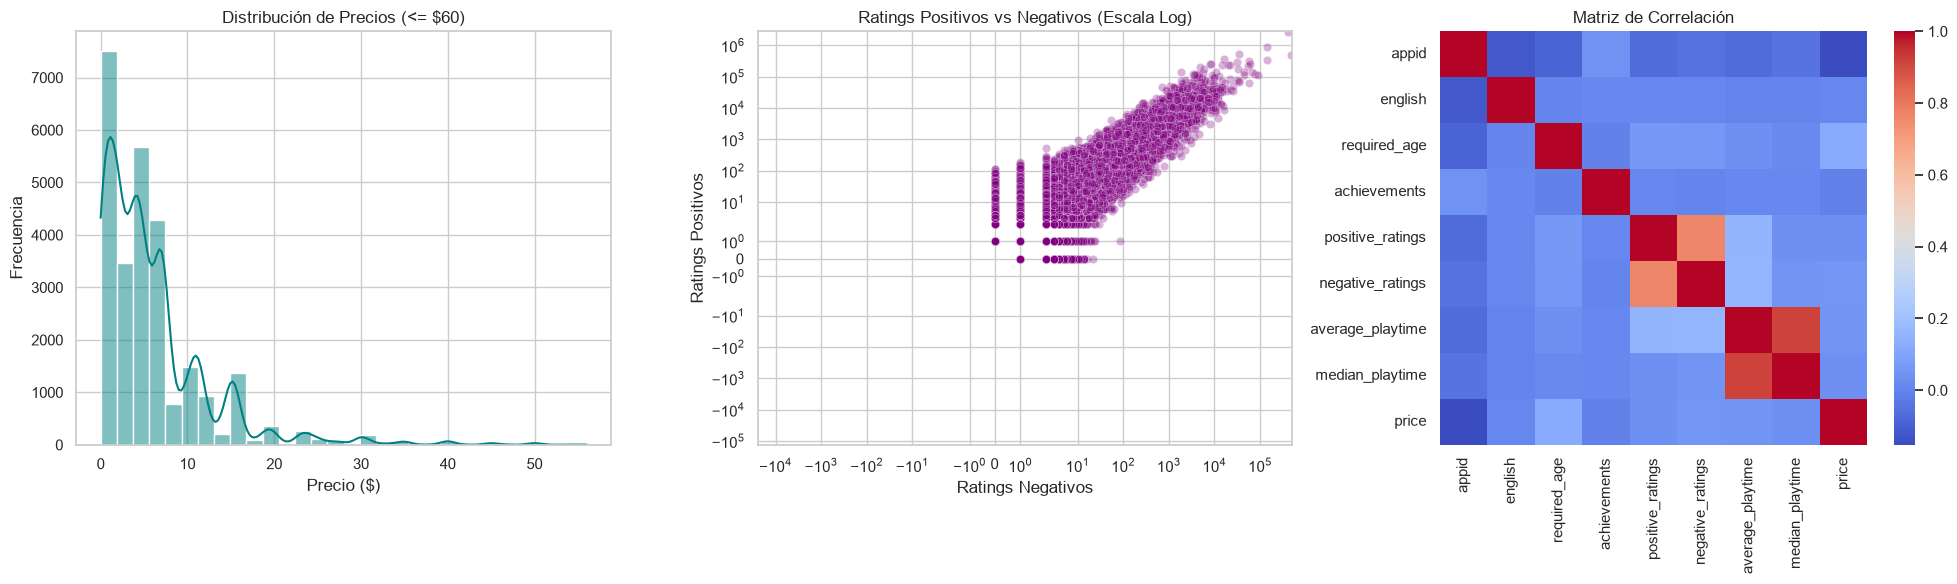

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Estadísticas descriptivas de variables numéricas
print("--- Estadísticas Descriptivas ---")
display(df.describe())


sns.set_theme(style="whitegrid")


fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 2. Visualización 1: Distribución de los precios
# Filtramos los juegos de más de $60 para poder ver bien la distribución principal
sns.histplot(df[df['price'] <= 60]['price'], bins=30, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Distribución de Precios (<= $60)')
axes[0].set_xlabel('Precio ($)')
axes[0].set_ylabel('Frecuencia')

# 3. Visualización 2: Relación entre Ratings Positivos vs Negativos
# Usamos escala logarítmica porque hay juegos con millones de reviews y otros con cero
sns.scatterplot(x='negative_ratings', y='positive_ratings', data=df, alpha=0.3, ax=axes[1], color='purple')
axes[1].set_xscale('symlog')
axes[1].set_yscale('symlog')
axes[1].set_title('Ratings Positivos vs Negativos (Escala Log)')
axes[1].set_xlabel('Ratings Negativos')
axes[1].set_ylabel('Ratings Positivos')

# 4. Visualización 3: Matriz de Correlación
# Seleccionamos solo las variables numéricas para ver cómo se relacionan entre sí
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', ax=axes[2], cbar=True)
axes[2].set_title('Matriz de Correlación')

plt.tight_layout()
plt.show()

Análisis Exploratorio de Datos (EDA)

A partir de las estadísticas descriptivas y las visualizaciones generadas, podemos extraer las siguientes conclusiones clave sobre el comportamiento de los juegos en Steam:


1. Asimetría en los Precios (Outliers):

La tabla de estadísticas revela una asimetría extrema en los precios y tiempos de juego. El 75% de los juegos cuestan $7.19 dólares o menos, y la mediana es de apenas $3.99. Sin embargo, existe un valor máximo de $421.99.
En el primer gráfico (Distribución de Precios <= $60) confirmamos que la inmensa mayoría de la tienda está dominada por juegos gratuitos o títulos indie que cuestan menos de $15 dólares. Los picos en el gráfico coinciden con los precios psicológicos típicos ($4.99, $9.99, $14.99). Esta distribución fuertemente sesgada a la derecha justifica la necesidad de filtrar los outliers extremos en nuestra etapa de limpieza para no sesgar el modelo.

2. Relación de Popularidad (Ratings):

El gráfico de dispersión en escala logarítmica muestra una clara correlación lineal positiva entre las reseñas positivas y negativas. Esto es un fenómeno de "volumen": los juegos más populares y jugados acumulan inherentemente una gran cantidad de reseñas en ambas direcciones.

3. Matriz de Correlación y Variables Redundantes:

El mapa de calor (Heatmap) nos permite identificar multicolinealidad:

Existe una correlación perfecta o casi perfecta entre average_playtime y median_playtime, así como entre positive_ratings y negative_ratings.

Correlación con el Precio: Notablemente, el precio (price) no muestra una correlación lineal fuerte con ninguna de las otras variables numéricas básicas (como la edad requerida o el número de logros). Esto nos indica que un modelo de regresión lineal simple probablemente tendría un mal desempeño, justificando nuestra elección futura de un modelo basado en árboles (Random Forest) que puede capturar relaciones no lineales complejas.

In [8]:
# --- Paso 3: Limpieza y Preparación de Datos ---

# 1. Tratamiento de valores faltantes
# Rellenamos los pocos valores nulos en texto con la etiqueta "Unknown"
df.fillna({'developer': 'Unknown', 'publisher': 'Unknown'}, inplace=True)

# 2. Corrección de tipos y extracción de características
# La columna 'owners' es categórica ('20000-50000'). Extraemos el límite inferior como número entero.
df['owners_numeric'] = df['owners'].apply(lambda x: int(x.split('-')[0]))

# 3. Tratamiento de Outliers
# Filtramos los juegos gratuitos (price == 0) y los valores atípicos extremos (price > 60)
# Esto enfoca nuestro modelo en predecir precios de juegos comerciales estándar.
df_clean = df[(df['price'] > 0) & (df['price'] <= 60)].copy()

# 4. Selección de características para el modelo base
# Eliminamos columnas de texto libre, listas delimitadas o IDs que no aportan valor lineal directo
cols_to_drop = ['appid', 'name', 'release_date', 'developer', 'publisher', 
                'platforms', 'categories', 'genres', 'steamspy_tags', 'owners']

df_model = df_clean.drop(columns=cols_to_drop)

print("--- Resumen tras la limpieza ---")
print(f"Tamaño original: {df.shape}")
print(f"Tamaño limpio: {df_model.shape}")
display(df_model.head())

--- Resumen tras la limpieza ---
Tamaño original: (27075, 19)
Tamaño limpio: (24485, 9)


,english,required_age,achievements,positive_ratings,negative_ratings,average_playtime,median_playtime,price,owners_numeric
0,1,0,0,124534,3339,17612,317,7.19,10000000
1,1,0,0,3318,633,277,62,3.99,5000000
2,1,0,0,3416,398,187,34,3.99,5000000
3,1,0,0,1273,267,258,184,3.99,5000000
4,1,0,0,5250,288,624,415,3.99,5000000


Decisiones de Limpieza y Preparación de Datos

Para asegurar la calidad de la información y preparar el conjunto de datos para nuestro modelo base, se tomaron las siguientes decisiones fundamentales, respaldadas por los hallazgos del Análisis Exploratorio:


1. Tratamiento de Valores Faltantes:

Identificamos que las columnas developer y publisher tenían una cantidad mínima de valores nulos (1 y 14 respectivamente). Al ser variables categóricas de texto, la decisión más conservadora fue imputarlos con la constante "Unknown" para no perder registros valiosos.

2. Conversión de Tipos y Extracción de Características:

La variable owners se presentaba en formato de texto indicando un rango estimado (ej. "20000-50000"). Dado que los algoritmos matemáticos no procesan rangos de texto, transformamos esta variable extrayendo su límite inferior para crear una nueva métrica puramente numérica (owners_numeric).

3. Tratamiento de Valores Atípicos (Outliers):

Basándonos en la fuerte asimetría detectada en el histograma del EDA, acotamos el dataset para enfocarnos en juegos comerciales estándar. Se eliminaron:

Juegos gratuitos (price == 0): Su éxito y distribución dependen de factores ajenos al precio de venta (ej. microtransacciones).

Outliers extremos (price > 60): Representan software especializado o bundles masivos que introducían ruido y sesgarían las predicciones del modelo.

4. Selección de Características (Feature Selection):

Para el modelo base (baseline), eliminamos columnas de identificadores (appid, name), fechas y texto libre (genres, categories). Si bien estas variables de texto contienen información valiosa, requieren técnicas de procesamiento avanzado (como One-Hot Encoding o NLP). Descartarlas temporalmente nos permite validar un flujo de trabajo (pipeline) rápido y limpio, reduciendo el dataset a 24,485 registros y 9 variables numéricas listas para el entrenamiento.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import mlflow
import mlflow.sklearn

# --- Paso 4: Entrenamiento del Modelo Base ---

# 1. Separar características (X) y variable objetivo (y)
X = df_model.drop(columns=['price'])
y = df_model['price']

# 2. Dividir en conjuntos de entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Configurar MLflow
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("TC5061_Notebook_Baseline_OjedaLuis")

# Iniciar el registro del experimento
with mlflow.start_run(run_name="Baseline_RandomForest"):
    
    # Entrenar el modelo
    rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
    rf_model.fit(X_train, y_train)
    
    # --- Paso 5: Evaluación del Modelo ---
    y_pred = rf_model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    print("--- Evaluación del Modelo Base ---")
    print(f"MAE (Error Absoluto Medio): ${mae:.2f}")
    print(f"RMSE (Raíz del Error Cuadrático Medio): ${rmse:.2f}")
    
    # --- Paso 6: Registro en MLflow ---
    mlflow.log_param("model_type", "RandomForestRegressor")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("random_state", 42)
    
    mlflow.log_metric("mae", mae)
    mlflow.log_metric("rmse", rmse)
    
    # Guardar el modelo como artefacto
    mlflow.sklearn.log_model(rf_model, 
        "baseline_model",
        skops_trusted_types=["sklearn.tree._tree.Tree"])
    
    print("\nExperimento registrado exitosamente en MLflow.")

--- Evaluación del Modelo Base ---
MAE (Error Absoluto Medio): $3.93
RMSE (Raíz del Error Cuadrático Medio): $5.68


2026/10/04 20:35:17 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



Experimento registrado exitosamente en MLflow.
🏃 View run Baseline_RandomForest at: http://127.0.0.1:5000/#/experiments/4/runs/68fc0d2590264a5aa1dece5549fac4f5
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


Entrenamiento, Evaluación y Registro del Modelo 

(MLOps)Paso 4: Entrenamiento del Modelo Base (Baseline)

Para establecer un punto de partida sólido, decidimos implementar un modelo de Random Forest Regressor (Bosque Aleatorio). La elección de un modelo basado en árboles, en lugar de una regresión lineal simple, se fundamenta en los hallazgos del EDA, donde observamos que las variables numéricas no tenían una correlación lineal directa con el precio.
Antes de entrenar, dividimos el conjunto de datos en un 80% para entrenamiento y un 20% para pruebas (test_size=0.2), garantizando que el modelo se evalúe sobre datos no vistos y previniendo el sobreajuste (data snooping bias).  

Paso 5: Evaluación e Interpretación de Métricas
Al tratarse de un problema de regresión, evaluamos el desempeño utilizando dos métricas coherentes con la predicción de precios:   MAE (Error Absoluto Medio) - $3.93: Esta métrica (norma $l_1$) nos indica que, en promedio, las predicciones de nuestro modelo se desvían por aproximadamente 3.93 dólares respecto al precio real del videojuego en la tienda de Steam.   RMSE (Raíz del Error Cuadrático Medio) - $5.68: Esta métrica (norma $l_2$) penaliza con mayor severidad los errores grandes. Al ser mayor que el MAE, nos indica que existen algunas predicciones con desviaciones más amplias.   

Interpretación: Considerando que filtramos juegos con precios de hasta $60, un error de ~$4-5 dólares es un baseline bastante aceptable para un modelo que solo utiliza características numéricas y de tiempo de juego. Esto nos confirma que el pipeline funciona, pero también nos señala que las variables de texto descartadas en la limpieza (como género, etiquetas y desarrollador) probablemente contienen la información crítica necesaria para reducir aún más este error en futuras iteraciones.

Paso 6: Registro de Experimentos en MLflow
Para asegurar la reproducibilidad del experimento, implementamos el seguimiento automatizado con MLflow Tracking. Durante la ejecución, registramos de forma centralizada:   Parámetros (Parameters): La configuración del modelo (n_estimators=100, random_state=42, model_type).Métricas (Metrics): Los resultados de nuestra evaluación (mae, rmse).Artefactos (Artifacts): El modelo entrenado serializado (junto con sus dependencias de entorno), lo que permitiría su futuro despliegue o consumo a través de una API REST.   

Este registro deja una evidencia auditable y nos proporciona la infraestructura necesaria para comparar este modelo base contra futuras versiones más complejas.  

Reflexión Final: Mejoras y Aplicación Profesional de MLOps

Al analizar el flujo que acabamos de construir, es evidente que, aunque logramos entrenar y registrar un modelo funcional, existen varias áreas de mejora si aplicamos prácticas maduras de MLOps. En primer lugar, la limpieza y transformación de datos se realizó de forma manual e imperativa. Para un entorno de producción, implementaría Pipelines de Scikit-Learn junto con ColumnTransformer para encapsular la imputación de nulos y la extracción numérica de rangos. Esto no solo evitaría la fuga de datos al separar estrictamente entrenamiento y prueba, sino que garantizaría la reproducibilidad del preprocesamiento al recibir nuevas instancias. Además, establecería un sistema de monitoreo continuo para detectar Data Drift; la industria de los videojuegos es dinámica, y un modelo estático perderá precisión rápidamente ante nuevas tendencias de mercado. Integrar el control de versiones en un ciclo CI/CD permitiría automatizar pruebas y realizar despliegues seguros y auditables.   

Estos aprendizajes resuenan directamente en mi día a día como Ingeniero de Soporte Técnico, particularmente al respaldar ecosistemas de impacto masivo como Outlook y Modern Work. En una escala empresarial, un modelo de Machine Learning integrado en un producto no puede operar como un simple script analítico; requiere la misma robustez y confiabilidad que cualquier otro componente crítico de TI corporativa. Si un modelo predictivo se degrada silenciosamente en producción y carece de monitoreo, el impacto se traduce de inmediato en interrupciones en la experiencia del usuario y una escalada de tickets de soporte técnico. Adoptar una cultura de MLOps aporta la trazabilidad, gobernanza y capacidad de respuesta necesarias para garantizar que los modelos se mantengan saludables en producción, asegurando así la continuidad del negocio y la estabilidad del servicio.

### Evidencia de Registro en MLflow
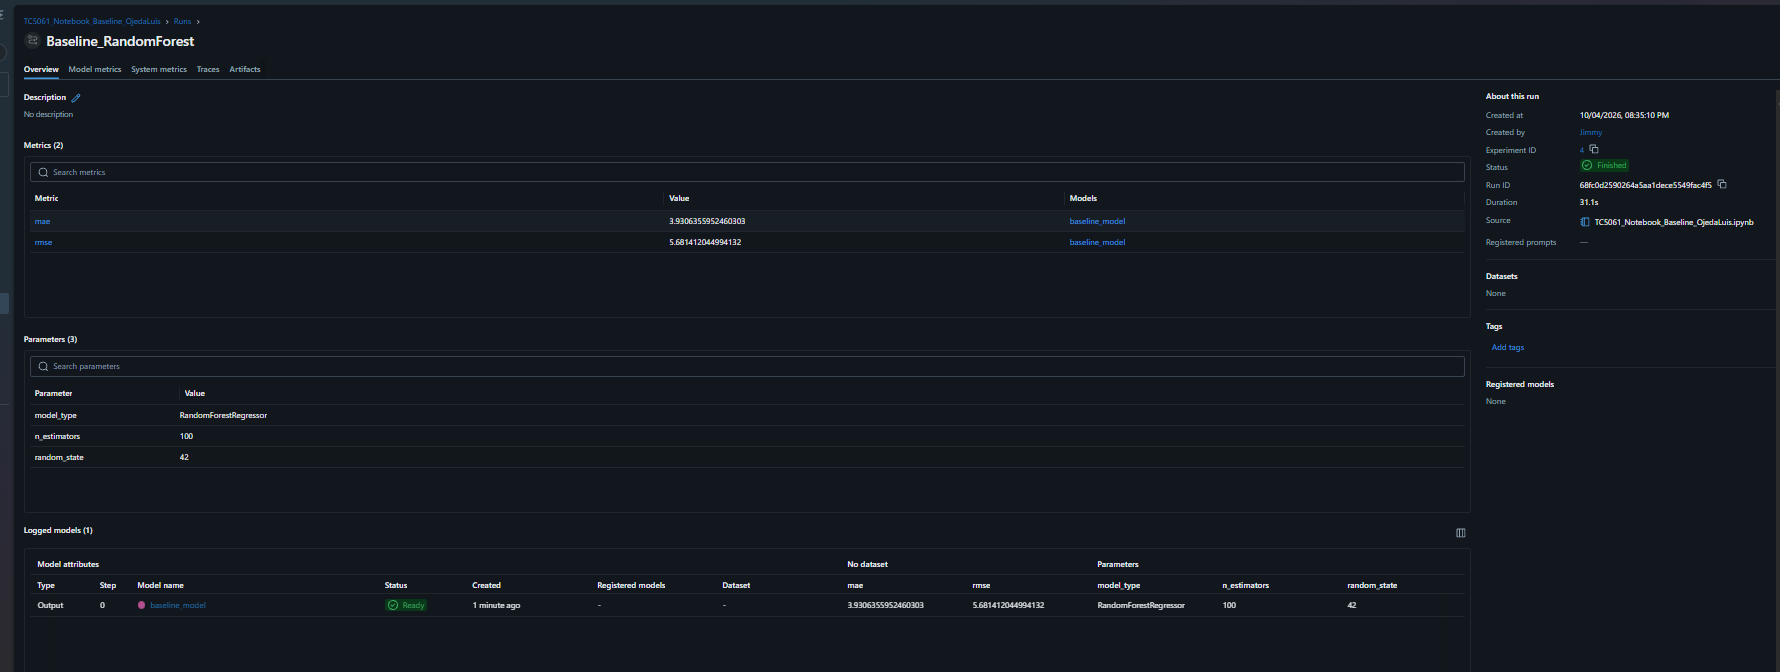